
# Lab Deep Learning — Backpropagation & Gradient Descent avec PyTorch

**Objectif du lab :** comprendre visuellement et mathématiquement la boucle d'entraînement d'un réseau de neurones :

$$
\boxed{\text{Forward Pass} \rightarrow \text{Loss} \rightarrow \text{Backpropagation} \rightarrow \text{Gradients} \rightarrow \text{Gradient Descent}}
$$

À la fin de ce notebook, vous saurez :
- calculer une prédiction ;
- calculer une fonction de perte ;
- comprendre la règle de la chaîne ;
- observer les gradients ;
- mettre à jour les poids ;
- étudier l'effet du *learning rate* ;
- tracer l'historique de la loss.


> **Professeur :** Mohammed BOUSMAH.  bousmah@gmail.com 

> **Niveau :** 5e année / Deep Learning  
> **Framework :** PyTorch


> **Compatibilité VS Code / Jupyter**  
> Toutes les formules utilisent `$...$` pour les formules en ligne et `$$...$$` pour les formules centrées.



## 0. Installation

Si PyTorch n'est pas encore installé :

```bash
uv add torch matplotlib
```

ou :

```bash
pip install torch matplotlib
```


## 1. Détection du type de GPU utilisé
 

| Matériel | Backend PyTorch | Device |
|---|---|---|
| NVIDIA | CUDA | `cuda` |
| AMD | ROCm / HIP | `cuda` |
| Intel | XPU | `xpu` |
| Apple M1/M2/M3/M4 | MPS | `mps` |
| Aucun accélérateur | CPU | `cpu` |

In [5]:

import torch
import matplotlib.pyplot as plt

print("PyTorch :", torch.__version__)
print("=== Détection du type de GPU utilisé ===")

device = torch.device("cpu")
device_name = "CPU"

# 1. NVIDIA CUDA
if torch.cuda.is_available() and torch.version.hip is None:
    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)

    print("GPU NVIDIA détecté")
    print("CUDA version :", torch.version.cuda)
    print("GPU :", device_name)

# 2. AMD ROCm
elif torch.cuda.is_available() and torch.version.hip is not None:
    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)

    print(" GPU AMD détecté")
    print("ROCm / HIP version :", torch.version.hip)
    print("GPU :", device_name)

# 3. Intel GPU via XPU
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")

    try:
        device_name = torch.xpu.get_device_name(0)
    except Exception:
        device_name = "Intel GPU"

    print(" GPU Intel détecté")
    print("Backend : XPU")
    print("GPU :", device_name)

# 4. Apple Silicon / MPS
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
    device_name = "Apple Silicon GPU"

    print(" GPU Apple détecté")
    print("Backend : MPS")

# 5. CPU
else:
    print("⚠️ Aucun GPU compatible détecté")
    print("Utilisation du CPU")

print("\n=== Device sélectionné ===")
print("Device :", device)
print("Nom    :", device_name)

torch.manual_seed(42)


PyTorch : 2.14.1
=== Détection du type de GPU utilisé ===
 GPU Apple détecté
Backend : MPS

=== Device sélectionné ===
Device : mps
Nom    : Apple Silicon GPU



## 2. Un neurone très simple

Nous allons commencer avec un modèle :

$$
\hat{y} = wx + b
$$

avec :

- $x$ : entrée ;
- $w$ : poids ;
- $b$ : biais ;
- $\hat{y}$ : prédiction.

Nous voulons apprendre $w$ et $b$ afin de rapprocher $\hat y$ de la cible $y$.


In [6]:

# Une seule observation
x = torch.tensor([2.0])
y = torch.tensor([10.0])

# Paramètres initiaux
w = torch.tensor([1.0], requires_grad=True)
b = torch.tensor([0.0], requires_grad=True)

# Forward pass
y_hat = w * x + b

print("x      =", x.item())
print("y réel =", y.item())
print("w      =", w.item())
print("b      =", b.item())
print("ŷ      =", y_hat.item())


x      = 2.0
y réel = 10.0
w      = 1.0
b      = 0.0
ŷ      = 2.0



## 3. Calcul de la fonction de perte

Nous utiliserons la Mean Squared Error sur un seul exemple :

$$
L = (\hat y-y)^2
$$

Pour simplifier la dérivation manuelle, on rencontre aussi souvent :

$$
L=\frac{1}{2}(\hat y-y)^2
$$

Le facteur $1/2$ permet d'annuler le $2$ apparaissant lors de la dérivation.


In [3]:

loss = (y_hat - y) ** 2

print("Prediction :", y_hat.item())
print("Cible      :", y.item())
print("Loss       :", loss.item())


Prediction : 2.0
Cible      : 10.0
Loss       : 64.0



## 4. Backpropagation

La rétropropagation calcule :

$$
\frac{\partial L}{\partial w}
\qquad\text{et}\qquad
\frac{\partial L}{\partial b}
$$

grâce à la **règle de la chaîne**.

Pour :

$$
\hat y = wx+b
$$

et :

$$
L=(\hat y-y)^2
$$

nous avons :

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial \hat y}
\frac{\partial \hat y}{\partial w}
$$

avec :

$$
\frac{\partial L}{\partial \hat y}=2(\hat y-y)
$$

et :

$$
\frac{\partial \hat y}{\partial w}=x
$$

donc :

$$
\boxed{
\frac{\partial L}{\partial w}
=
2(\hat y-y)x
}
$$

De même :

$$
\boxed{
\frac{\partial L}{\partial b}
=
2(\hat y-y)
}
$$


In [4]:

# Calcul manuel
manual_dw = 2 * (y_hat.detach() - y) * x
manual_db = 2 * (y_hat.detach() - y)

print("Gradient manuel dL/dw =", manual_dw.item())
print("Gradient manuel dL/db =", manual_db.item())

# Autograd PyTorch
loss.backward()

print("\nGradient PyTorch dL/dw =", w.grad.item())
print("Gradient PyTorch dL/db =", b.grad.item())


Gradient manuel dL/dw = -32.0
Gradient manuel dL/db = -16.0

Gradient PyTorch dL/dw = -32.0
Gradient PyTorch dL/db = -16.0



### Interprétation

Le gradient indique **comment la loss varie lorsque le paramètre varie**.

- gradient positif : augmenter le poids augmente localement la loss ;
- gradient négatif : augmenter le poids diminue localement la loss ;
- gradient proche de zéro : on est localement proche d'un point stationnaire.

> La **backpropagation calcule les gradients**.  
> La **descente de gradient utilise ces gradients pour modifier les paramètres**.



## 5. Gradient Descent

La mise à jour d'un paramètre suit :

$$
\boxed{
w_{\text{new}}
=
w_{\text{old}}
-
\eta
\frac{\partial L}{\partial w}
}
$$

et :

$$
\boxed{
b_{\text{new}}
=
b_{\text{old}}
-
\eta
\frac{\partial L}{\partial b}
}
$$

où $\eta$ est le **learning rate**.


In [7]:

learning_rate = 0.01

print("AVANT")
print("w =", w.item(), "| b =", b.item(), "| loss =", loss.item())

with torch.no_grad():
    w -= learning_rate * w.grad
    b -= learning_rate * b.grad

print("\nAPRÈS une étape de Gradient Descent")
print("w =", w.item(), "| b =", b.item())

# Important : remise à zéro des gradients
w.grad.zero_()
b.grad.zero_()


AVANT
w = 1.0 | b = 0.0 | loss = 64.0

APRÈS une étape de Gradient Descent
w = 1.3199999332427979 | b = 0.1599999964237213


tensor([0.])


## 6. Boucle d'entraînement complète

À chaque itération :

1. **Forward pass**
2. **Loss**
3. **Backpropagation**
4. **Gradient Descent**
5. **Reset des gradients**


In [8]:

# Réinitialisation
w = torch.tensor([1.0], requires_grad=True)
b = torch.tensor([0.0], requires_grad=True)

learning_rate = 0.01
epochs = 30

loss_history = []
w_history = []
b_history = []

for epoch in range(epochs):
    # 1. Forward
    y_hat = w * x + b

    # 2. Loss
    loss = (y_hat - y) ** 2

    # Sauvegarde avant mise à jour
    loss_history.append(loss.item())
    w_history.append(w.item())
    b_history.append(b.item())

    # 3. Backpropagation
    loss.backward()

    # Affichage de quelques étapes
    if epoch < 5 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d} | "
            f"ŷ={y_hat.item():7.4f} | "
            f"Loss={loss.item():9.5f} | "
            f"dL/dw={w.grad.item():9.5f} | "
            f"dL/db={b.grad.item():9.5f}"
        )

    # 4. Gradient descent
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    # 5. Reset des gradients
    w.grad.zero_()
    b.grad.zero_()

print("\nParamètres finaux")
print("w =", w.item())
print("b =", b.item())
print("Prédiction finale =", (w*x+b).item())


Epoch 00 | ŷ= 2.0000 | Loss= 64.00000 | dL/dw=-32.00000 | dL/db=-16.00000
Epoch 01 | ŷ= 2.8000 | Loss= 51.84000 | dL/dw=-28.80000 | dL/db=-14.40000
Epoch 02 | ŷ= 3.5200 | Loss= 41.99041 | dL/dw=-25.92000 | dL/db=-12.96000
Epoch 03 | ŷ= 4.1680 | Loss= 34.01223 | dL/dw=-23.32800 | dL/db=-11.66400
Epoch 04 | ŷ= 4.7512 | Loss= 27.54990 | dL/dw=-20.99520 | dL/db=-10.49760
Epoch 05 | ŷ= 5.2761 | Loss= 22.31542 | dL/dw=-18.89568 | dL/db= -9.44784
Epoch 10 | ŷ= 7.2106 | Loss=  7.78091 | dL/dw=-11.15771 | dL/db= -5.57886
Epoch 15 | ŷ= 8.3529 | Loss=  2.71304 | dL/dw= -6.58852 | dL/db= -3.29426
Epoch 20 | ŷ= 9.0274 | Loss=  0.94598 | dL/dw= -3.89046 | dL/db= -1.94523
Epoch 25 | ŷ= 9.4257 | Loss=  0.32984 | dL/dw= -2.29727 | dL/db= -1.14864

Paramètres finaux
w = 4.064348220825195
b = 1.5321742296218872
Prédiction finale = 9.660870552062988



## 7. Loss History

Une loss décroissante indique généralement que l'optimisation progresse.

Elle n'est cependant **pas obligatoirement strictement décroissante à chaque étape**, notamment avec SGD ou les mini-batches.


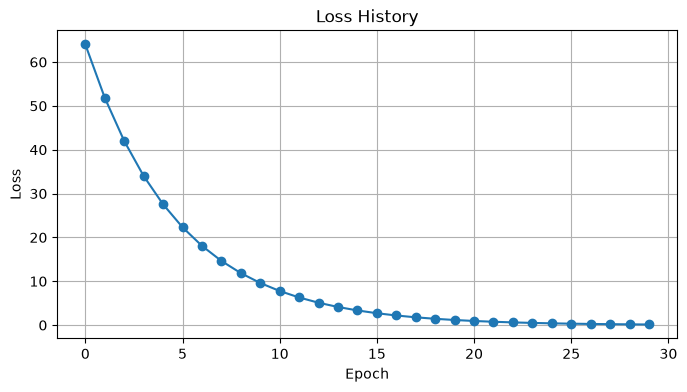

In [9]:

plt.figure(figsize=(8, 4))
plt.plot(loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss History")
plt.grid(True)
plt.show()



## 8. Évolution des paramètres


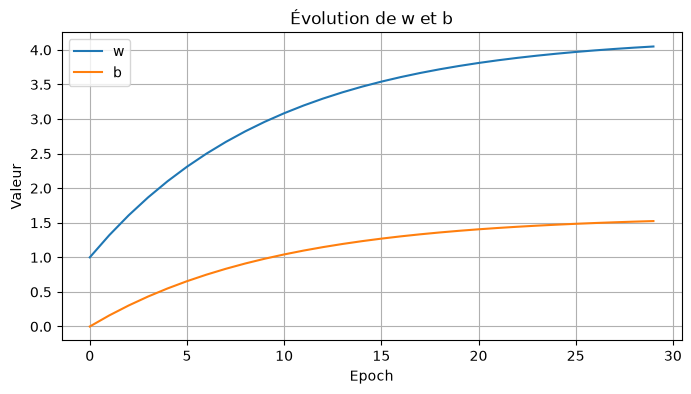

In [10]:

plt.figure(figsize=(8, 4))
plt.plot(w_history, label="w")
plt.plot(b_history, label="b")
plt.xlabel("Epoch")
plt.ylabel("Valeur")
plt.title("Évolution de w et b")
plt.legend()
plt.grid(True)
plt.show()



# 9. Expérience : effet du Learning Rate

Nous allons comparer plusieurs valeurs de :

$$
\eta
$$

Le but est d'observer trois comportements :

- **learning rate faible** : convergence lente ;
- **learning rate adapté** : convergence rapide ;
- **learning rate trop grand** : oscillation ou divergence.


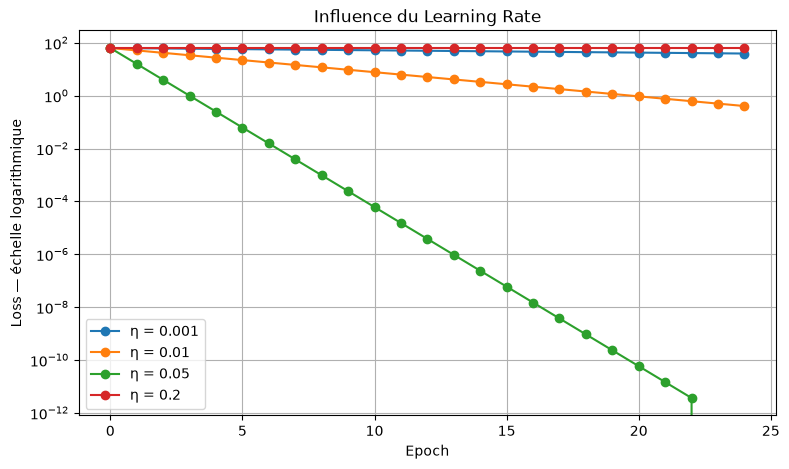

In [11]:

def train_with_lr(lr, epochs=25):
    w = torch.tensor([1.0], requires_grad=True)
    b = torch.tensor([0.0], requires_grad=True)

    history = []

    for _ in range(epochs):
        y_hat = w * x + b
        loss = (y_hat - y) ** 2
        history.append(loss.item())

        loss.backward()

        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad

        w.grad.zero_()
        b.grad.zero_()

    return history

learning_rates = [0.001, 0.01, 0.05, 0.2]

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    history = train_with_lr(lr)
    plt.plot(history, marker="o", label=f"η = {lr}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss — échelle logarithmique")
plt.title("Influence du Learning Rate")
plt.legend()
plt.grid(True)
plt.show()



## 10. Observer les gradients en temps réel


In [13]:

w = torch.tensor([1.0], requires_grad=True)
b = torch.tensor([0.0], requires_grad=True)

lr = 0.01

print(f"{'Epoch':>5} | {'w':>8} | {'b':>8} | {'ŷ':>8} | {'Loss':>10} | {'dL/dw':>10} | {'dL/db':>10}")
print("-" * 82)

for epoch in range(10):
    y_hat = w * x + b
    loss = (y_hat - y) ** 2

    loss.backward()

    print(
        f"{epoch:5d} | "
        f"{w.item():8.4f} | "
        f"{b.item():8.4f} | "
        f"{y_hat.item():8.4f} | "
        f"{loss.item():10.5f} | "
        f"{w.grad.item():10.5f} | "
        f"{b.grad.item():10.5f}"
    )

    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    w.grad.zero_()
    b.grad.zero_()


Epoch |        w |        b |        ŷ |       Loss |      dL/dw |      dL/db
----------------------------------------------------------------------------------
    0 |   1.0000 |   0.0000 |   2.0000 |   64.00000 |  -32.00000 |  -16.00000
    1 |   1.3200 |   0.1600 |   2.8000 |   51.84000 |  -28.80000 |  -14.40000
    2 |   1.6080 |   0.3040 |   3.5200 |   41.99041 |  -25.92000 |  -12.96000
    3 |   1.8672 |   0.4336 |   4.1680 |   34.01223 |  -23.32800 |  -11.66400
    4 |   2.1005 |   0.5502 |   4.7512 |   27.54990 |  -20.99520 |  -10.49760
    5 |   2.3104 |   0.6552 |   5.2761 |   22.31542 |  -18.89568 |   -9.44784
    6 |   2.4994 |   0.7497 |   5.7485 |   18.07549 |  -17.00611 |   -8.50306
    7 |   2.6694 |   0.8347 |   6.1736 |   14.64115 |  -15.30550 |   -7.65275
    8 |   2.8225 |   0.9113 |   6.5563 |   11.85933 |  -13.77495 |   -6.88748
    9 |   2.9603 |   0.9801 |   6.9006 |    9.60606 |  -12.39746 |   -6.19873



# 11. Version PyTorch avec `nn.Module`

Dans un vrai projet, on ne met généralement pas les paramètres à jour manuellement.

PyTorch fournit :

- `nn.Module` pour le modèle ;
- `nn.MSELoss()` pour la fonction de perte ;
- `torch.optim.SGD` pour la descente de gradient ;
- `optimizer.zero_grad()` pour remettre les gradients à zéro ;
- `optimizer.step()` pour effectuer la mise à jour.


In [5]:

import torch.nn as nn

# Dataset très simple : y = 4x + 2
X = torch.tensor([[1.0], [2.0], [3.0], [4.0], [5.0]])
Y = 4 * X + 2

model = nn.Linear(1, 1)

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

loss_history_model = []

for epoch in range(200):
    # 1. Forward
    predictions = model(X)

    # 2. Loss
    loss = criterion(predictions, Y)

    # 3. Reset gradients
    optimizer.zero_grad()

    # 4. Backpropagation
    loss.backward()

    # 5. Mise à jour
    optimizer.step()

    loss_history_model.append(loss.item())

    if epoch % 40 == 0:
        weight = model.weight.item()
        bias = model.bias.item()
        print(
            f"Epoch {epoch:03d} | "
            f"Loss={loss.item():.6f} | "
            f"w={weight:.4f} | "
            f"b={bias:.4f}"
        )

print("\nParamètres appris")
print("w =", model.weight.item())
print("b =", model.bias.item())


Epoch 000 | Loss=225.862457 | w=0.7622 | b=1.1943
Epoch 040 | Loss=0.001001 | w=3.9795 | b=2.0739
Epoch 080 | Loss=0.000764 | w=3.9821 | b=2.0645
Epoch 120 | Loss=0.000582 | w=3.9844 | b=2.0564
Epoch 160 | Loss=0.000444 | w=3.9864 | b=2.0492

Paramètres appris
w = 3.988051652908325
b = 2.043137311935425


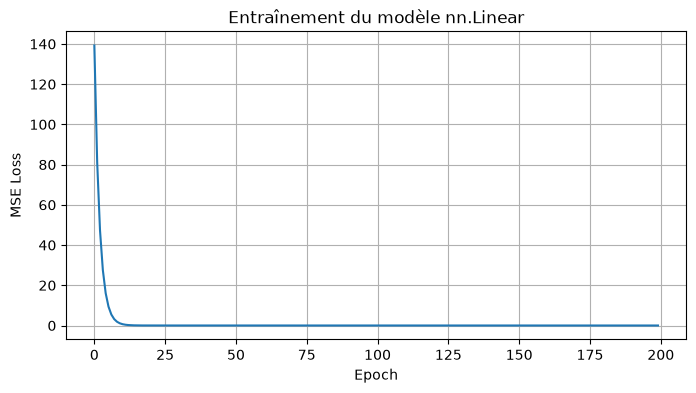

In [15]:

plt.figure(figsize=(8, 4))
plt.plot(loss_history_model)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Entraînement du modèle nn.Linear")
plt.grid(True)
plt.show()



# 12. Vérifier les gradients d'un vrai modèle

PyTorch stocke les gradients dans l'attribut `.grad` de chaque paramètre.


In [16]:

# Un forward/backward supplémentaire pour inspection
optimizer.zero_grad()
predictions = model(X)
loss = criterion(predictions, Y)
loss.backward()

for name, parameter in model.named_parameters():
    print(name)
    print("Valeur    :", parameter.data)
    print("Gradient  :", parameter.grad)
    print()


weight
Valeur    : tensor([[4.0358]])
Gradient  : tensor([[0.0121]])

bias
Valeur    : tensor([1.8708])
Gradient  : tensor([-0.0437])




# 13. Exercice étudiant

Modifiez le notebook afin d'étudier :

### Exercice A
Essayez :

$$
\eta \in \{0.0001,\;0.001,\;0.01,\;0.1,\;0.5\}
$$

Pour chaque valeur :

1. tracez la loss ;
2. notez si le modèle converge ;
3. comparez la vitesse de convergence ;
4. identifiez une éventuelle divergence.

### Exercice B
Remplacez :

$$
y = 4x+2
$$

par :

$$
y = 7x-3
$$

et vérifiez que PyTorch retrouve approximativement :

$$
w \approx 7,\qquad b \approx -3
$$

### Exercice C
Expliquez avec vos propres mots la différence entre :

- Forward Pass
- Loss
- Backpropagation
- Gradient
- Gradient Descent
- Learning Rate

### Exercice D — Question de réflexion
Pourquoi faut-il appeler :

```python
optimizer.zero_grad()
```

avant `loss.backward()` ?



# 14. Synthèse

La boucle d'apprentissage peut être résumée ainsi :

$$
x
\rightarrow
\boxed{\text{Forward}}
\rightarrow
\hat y
\rightarrow
\boxed{\text{Loss}}
\rightarrow
L
\rightarrow
\boxed{\text{Backpropagation}}
\rightarrow
\nabla L
\rightarrow
\boxed{\text{Gradient Descent}}
\rightarrow
\text{nouveaux paramètres}
$$

### À retenir

$$
\boxed{
\text{Backpropagation}
\Rightarrow
\text{calcul des gradients}
}
$$

$$
\boxed{
\text{Gradient Descent}
\Rightarrow
\text{mise à jour des paramètres}
}
$$

et :

$$
\boxed{
w \leftarrow w-\eta\frac{\partial L}{\partial w}
}
$$


# 15. Perceptron et frontière de décision

Considérons un perceptron à deux entrées :

$$
z=b+w_1x_1+w_2x_2
$$

La sortie est obtenue avec une fonction sigmoïde :

$$
\hat{y}=\sigma(z)=\frac{1}{1+e^{-z}}
$$

Pour l'exemple suivant :

$$
z=1+3x_1-2x_2
$$

nous avons $b=1$, $w_1=3$ et $w_2=-2$.


## 15.1 Frontière de décision

La frontière de décision correspond à :

$$
z=0
$$

Donc :

$$
1+3x_1-2x_2=0
$$

et :

$$
x_2=\frac{1+3x_1}{2}
$$

Cette droite sépare l'espace en deux régions :

$$
z>0 \Rightarrow \hat{y}>0.5
$$

$$
z<0 \Rightarrow \hat{y}<0.5
$$


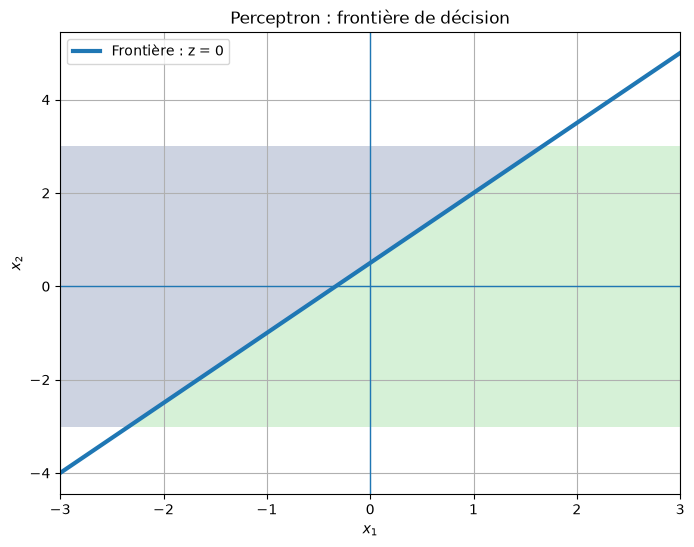

In [17]:
import numpy as np
import matplotlib.pyplot as plt

b = 1.0
w1 = 3.0
w2 = -2.0

x1 = np.linspace(-3, 3, 300)
x2_boundary = -(b + w1 * x1) / w2

xx1, xx2 = np.meshgrid(
    np.linspace(-3, 3, 300),
    np.linspace(-3, 3, 300)
)
z = b + w1 * xx1 + w2 * xx2

plt.figure(figsize=(8, 6))
plt.contourf(xx1, xx2, z > 0, alpha=0.25)
plt.plot(x1, x2_boundary, linewidth=3, label='Frontière : z = 0')
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Perceptron : frontière de décision')
plt.legend()
plt.grid(True)
plt.show()


## 15.2 Sigmoïde et seuil de décision

La sigmoïde transforme $z$ en une valeur comprise entre 0 et 1 :

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Comme :

$$
\sigma(0)=0.5
$$

on obtient naturellement :

$$
\hat{y}>0.5 \Rightarrow \text{classe 1}
$$

$$
\hat{y}<0.5 \Rightarrow \text{classe 0}
$$


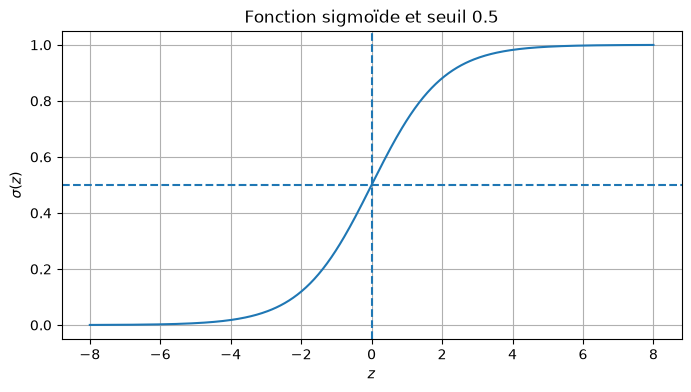

In [18]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z_values = np.linspace(-8, 8, 400)
y_values = sigmoid(z_values)

plt.figure(figsize=(8, 4))
plt.plot(z_values, y_values)
plt.axhline(0.5, linestyle='--')
plt.axvline(0, linestyle='--')
plt.xlabel('$z$')
plt.ylabel('$\\sigma(z)$')
plt.title('Fonction sigmoïde et seuil 0.5')
plt.grid(True)
plt.show()


## 15.3 Visualisation interactive

Modifiez $w_1$, $w_2$ et $b$ pour observer le déplacement et la rotation de la frontière de décision.

Si les widgets ne s'affichent pas dans VS Code, installez :

ipywidgets est une bibliothèque Python qui permet d’ajouter des éléments interactifs dans un notebook Jupyter.
```bash
uv add ipywidgets
```


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def plot_perceptron(w1=3.0, w2=-2.0, b=1.0):
    x1 = np.linspace(-3, 3, 300)
    xx1, xx2 = np.meshgrid(
        np.linspace(-3, 3, 300),
        np.linspace(-3, 3, 300)
    )
    z = b + w1 * xx1 + w2 * xx2

    plt.figure(figsize=(8, 6))
    plt.contourf(xx1, xx2, z > 0, alpha=0.25)

    if abs(w2) > 1e-8:
        x2_boundary = -(b + w1 * x1) / w2
        plt.plot(x1, x2_boundary, linewidth=3)
    elif abs(w1) > 1e-8:
        plt.axvline(-b / w1, linewidth=3)

    plt.xlim(-3, 3)
    plt.ylim(-3, 3)
    plt.axhline(0, linewidth=1)
    plt.axvline(0, linewidth=1)
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.title(f'$z = {b:.1f} + {w1:.1f}x_1 + {w2:.1f}x_2$')
    plt.grid(True)
    plt.show()

interact(
    plot_perceptron,
    w1=FloatSlider(value=3.0, min=-5.0, max=5.0, step=0.1),
    w2=FloatSlider(value=-2.0, min=-5.0, max=5.0, step=0.1),
    b=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1)
);


interactive(children=(FloatSlider(value=3.0, description='w1', max=5.0, min=-5.0), FloatSlider(value=-2.0, des…

## 15.4 À retenir

$$
\boxed{z=b+w_1x_1+w_2x_2}
$$

$$
\boxed{\hat{y}=\sigma(z)}
$$

$$
\boxed{w_1x_1+w_2x_2+b=0}
$$

La dernière équation définit la **frontière de décision**.

### Questions pédagogiques

1. Que se passe-t-il si on augmente uniquement le biais $b$ ?
2. Que se passe-t-il si on change le signe de $w_1$ ?
3. Que se passe-t-il si on change le signe de $w_2$ ?
4. Que devient la frontière lorsque $w_2$ est proche de zéro ?


In [10]:
import time

start = time.time()
print("start :",start, "secondes")
import torch
import matplotlib.pyplot as plt
import ipywidgets

print("Temps de chargement :", time.time() - start, "secondes")

start : 1791404502.254289 secondes
Temps de chargement : 0.00011110305786132812 secondes
